<a href="https://colab.research.google.com/github/jaeheechillin3/pytorch_projects/blob/main/vit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Imports

In [58]:
!pip -q install einops

In [59]:
import torch
import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import transforms
from torchvision.datasets import FashionMNIST
from einops.layers.torch import Rearrange

import matplotlib.pyplot as plt

## Configuration

In [60]:
IMAGE_SIZE = 28
PATCH_SIZE = 4
EMBED_DIM = 64
NUM_HEADS = 4
NUM_LAYERS = 4
NUM_CLASSES = 10
DROPOUT = 0.1

BATCH_SIZE = 128
LEARNING_RATE = 1e-3
EPOCHS = 15

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Model

In [61]:
class PatchEmbedding(nn.Sequential):
    def __init__(self, channels, patch_size, embed_dim):
        super().__init__(
            Rearrange(
                "b c (h p1) (w p2) -> b (h w) (p1 p2 c)",
                p1=patch_size,
                p2=patch_size,
            ),
            nn.Linear(patch_size * patch_size * channels, embed_dim),
        )

In [62]:
class Attention(nn.Module):
    def __init__(self, dim, heads, dropout):
        super().__init__()
        self.attention = nn.MultiheadAttention(
            embed_dim=dim,
            num_heads=heads,
            dropout=dropout,
            batch_first=True,
        )

    def forward(self, x):
        output, _ = self.attention(x, x, x, need_weights=False)
        return output

In [63]:
class FeedForward(nn.Sequential):
    def __init__(self, dim, hidden_dim, dropout):
        super().__init__(
            nn.Linear(dim, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, dim),
            nn.Dropout(dropout),
        )

In [64]:
class TransformerBlock(nn.Module):
    def __init__(self, dim, heads, dropout):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.norm2 = nn.LayerNorm(dim)
        self.attention = Attention(dim, heads, dropout)
        self.feed_forward = FeedForward(dim, 4 * dim, dropout)

    def forward(self, x):
        x = x + self.attention(self.norm1(x))
        x = x + self.feed_forward(self.norm2(x))
        return x

In [65]:
class ViT(nn.Module):
    def __init__(
        self,
        image_size=IMAGE_SIZE,
        patch_size=PATCH_SIZE,
        channels=1,
        embed_dim=EMBED_DIM,
        heads=NUM_HEADS,
        layers=NUM_LAYERS,
        num_classes=NUM_CLASSES,
        dropout=DROPOUT,
    ):
        super().__init__()

        if image_size % patch_size != 0:
            raise ValueError("image_size must be divisible by patch_size.")
        if embed_dim % heads != 0:
            raise ValueError("embed_dim must be divisible by heads.")

        self.image_size = image_size
        num_patches = (image_size // patch_size) ** 2

        self.patch_embedding = PatchEmbedding(
            channels, patch_size, embed_dim
        )
        self.cls_token = nn.Parameter(torch.empty(1, 1, embed_dim))
        self.pos_embedding = nn.Parameter(
            torch.empty(1, num_patches + 1, embed_dim)
        )

        nn.init.normal_(self.cls_token, std=0.02)
        nn.init.normal_(self.pos_embedding, std=0.02)

        self.embedding_dropout = nn.Dropout(dropout)
        self.encoder = nn.Sequential(
            *[
                TransformerBlock(embed_dim, heads, dropout)
                for _ in range(layers)
            ]
        )
        self.head = nn.Sequential(
            nn.LayerNorm(embed_dim),
            nn.Linear(embed_dim, num_classes),
        )

    def forward(self, images):
        if images.shape[-2:] != (self.image_size, self.image_size):
            raise ValueError(
                f"Expected images of size "
                f"{self.image_size} × {self.image_size}."
            )

        x = self.patch_embedding(images)
        cls_tokens = self.cls_token.expand(x.size(0), -1, -1)
        x = torch.cat((cls_tokens, x), dim=1)
        x = self.embedding_dropout(x + self.pos_embedding)
        x = self.encoder(x)

        return self.head(x[:, 0])


## Training and Evaluation

In [66]:
def train_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_samples += labels.size(0)

    return total_loss / total_samples, total_correct / total_samples

In [67]:
@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        logits = model(images)
        loss = criterion(logits, labels)

        total_loss += loss.item() * labels.size(0)
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_samples += labels.size(0)

    return total_loss / total_samples, total_correct / total_samples

In [70]:
def main():
    torch.manual_seed(42)

    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(mean=(0.5,), std=(0.5,)),
    ])

    trainval_dataset = FashionMNIST(
        root="./data",
        train=True,
        transform=transform,
        download=True,
    )

    test_dataset = FashionMNIST(
        root="./data",
        train=False,
        transform=transform,
        download=True,
    )

    train_dataset, val_dataset, _ = random_split(
        trainval_dataset,
        [30_000, 5_000, 25_000],
        generator=torch.Generator().manual_seed(42),
    )

    loader_options = {
        "batch_size": BATCH_SIZE,
        "num_workers": 2,
        "pin_memory": DEVICE.type == "cuda",
    }
    train_loader = DataLoader(
        train_dataset, shuffle=True, **loader_options
    )
    val_loader = DataLoader(
        val_dataset, shuffle=False, **loader_options
    )
    test_loader = DataLoader(
        test_dataset, shuffle=False, **loader_options
    )

    model = ViT().to(DEVICE)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=LEARNING_RATE
    )
    criterion = nn.CrossEntropyLoss()

    print(f"Device: {DEVICE}")
    print(
        f"Training: {len(train_dataset):,} | "
        f"Validation: {len(val_dataset):,} | "
        f"Test: {len(test_dataset):,}"
    )

    # Record metrics for plotting afterward.
    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": [],
    }

    for epoch in range(1, EPOCHS + 1):
        train_loss, train_accuracy = train_epoch(
            model, train_loader, optimizer, criterion
        )
        val_loss, val_accuracy = evaluate(
            model, val_loader, criterion
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_accuracy"].append(val_accuracy)

        print(
            f"Epoch {epoch:2d}/{EPOCHS} | "
            f"Train loss: {train_loss:.4f}, "
            f"accuracy: {train_accuracy:.1%} | "
            f"Val loss: {val_loss:.4f}, "
            f"accuracy: {val_accuracy:.1%}"
        )

    test_loss, test_accuracy = evaluate(
        model, test_loader, criterion
    )
    print(
        f"\nTest loss: {test_loss:.4f} | "
        f"Test accuracy: {test_accuracy:.1%}"
    )

    # Keep the trained model and metrics available to later cells.
    return model, test_dataset, history


In [71]:
if __name__ == "__main__":
    model, test_dataset, history = main()

Device: cuda
Training: 30,000 | Validation: 5,000 | Test: 10,000
Epoch  1/15 | Train loss: 1.1000, accuracy: 59.8% | Val loss: 0.7191, accuracy: 73.1%
Epoch  2/15 | Train loss: 0.6174, accuracy: 77.5% | Val loss: 0.5554, accuracy: 80.2%
Epoch  3/15 | Train loss: 0.5235, accuracy: 80.9% | Val loss: 0.4796, accuracy: 82.7%
Epoch  4/15 | Train loss: 0.4685, accuracy: 83.0% | Val loss: 0.4312, accuracy: 84.1%
Epoch  5/15 | Train loss: 0.4450, accuracy: 83.8% | Val loss: 0.4463, accuracy: 83.0%
Epoch  6/15 | Train loss: 0.4131, accuracy: 84.6% | Val loss: 0.4023, accuracy: 85.3%
Epoch  7/15 | Train loss: 0.3982, accuracy: 85.3% | Val loss: 0.4023, accuracy: 85.7%
Epoch  8/15 | Train loss: 0.3838, accuracy: 85.8% | Val loss: 0.3924, accuracy: 85.9%
Epoch  9/15 | Train loss: 0.3699, accuracy: 86.4% | Val loss: 0.3798, accuracy: 86.2%
Epoch 10/15 | Train loss: 0.3563, accuracy: 86.8% | Val loss: 0.3846, accuracy: 86.1%
Epoch 11/15 | Train loss: 0.3446, accuracy: 87.2% | Val loss: 0.3536, accur

## Training Loss Curves

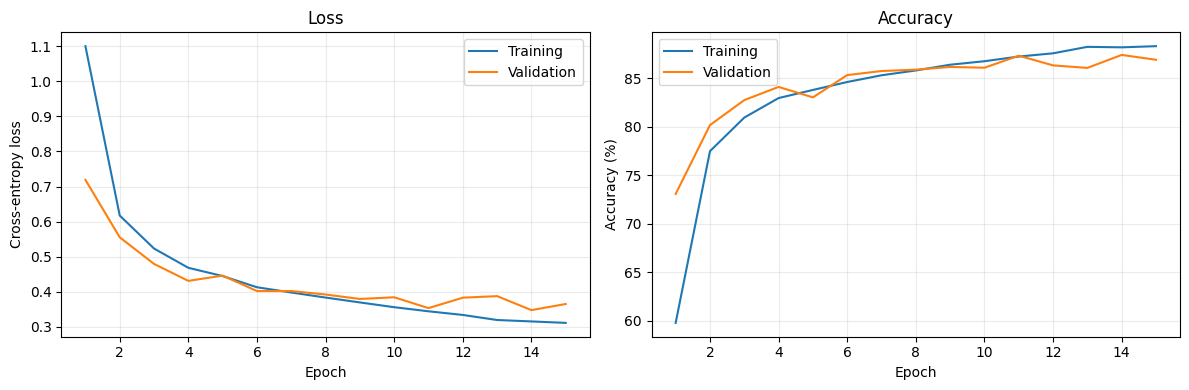

In [72]:
epochs = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, history["train_loss"], label="Training")
axes[0].plot(epochs, history["val_loss"], label="Validation")
axes[0].set(
    title="Loss",
    xlabel="Epoch",
    ylabel="Cross-entropy loss",
)

axes[1].plot(
    epochs,
    [100 * value for value in history["train_accuracy"]],
    label="Training",
)
axes[1].plot(
    epochs,
    [100 * value for value in history["val_accuracy"]],
    label="Validation",
)
axes[1].set(
    title="Accuracy",
    xlabel="Epoch",
    ylabel="Accuracy (%)",
)

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()